# Binary phase separation and periodic connectivity

I compare mean compositions 0.5 and 0.4 using the same zero-mean perturbation. Composition c, energy coefficients, grid spacing and time are dimensionless. The 256² simulation uses dt=0.2, 2000 steps and seed 20260921. I measure four-neighbor connectivity at thresholds 0.45, 0.5 and 0.55. Mean composition and thresholded phase fraction are different quantities.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy scikit-image matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
output = 'bicontinuity-results'

## Step 3: Prepare the next part of the calculation

I define `SEED`, `GRID_SIZE`, `GRID_SPACING`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
from collections import deque
from pathlib import Path
import json
import sys
import numpy as np
from skimage.io import imsave
SEED = 20260921
GRID_SIZE = 256
GRID_SPACING = 1.0

## Step 4: Prepare the next part of the calculation

I define `TIME_STEP`, `NUMBER_OF_STEPS`, `A`, `MOBILITY`, `KAPPA`, `MEAN_COMPOSITIONS`, `THRESHOLDS`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [4]:
TIME_STEP = 0.2
NUMBER_OF_STEPS = 2000
A = 1.0
MOBILITY = 1.0
KAPPA = 1.0
MEAN_COMPOSITIONS = (0.5, 0.4)
THRESHOLDS = (0.45, 0.5, 0.55)

## Step 5: Visit connected pixels and record wrapping

I start at one occupied pixel and add its edge-sharing neighbors to a queue. Periodic indices wrap at the image boundary. Unwrapped positions continue beyond that boundary. Two visits to the same pixel with different unwrapped positions reveal a winding loop. Coordinate flags indicate wrapping along an axis; they do not measure the number of independent winding directions.

In [5]:
def connectivity(mask):
    """Count regions and detect loops winding around the periodic domain.

    A True pixel belongs to the region we are measuring. We start at an
    unvisited True pixel and visit every neighbor connected to it. This gives
    one component. Then we start again at the next unvisited True pixel.

    Array coordinates wrap at the boundaries. Alongside them, we track
    unwrapped coordinates, which continue beyond the box. If two paths reach
    the SAME pixel with different unwrapped coordinates, their difference
    reveals a loop winding around the periodic box. Simply joining across
    an edge is not enough: a small island straddling an edge need not wrap.
    """
    size_x, size_y = mask.shape
    visited = np.zeros(mask.shape, dtype=bool)
    unwrapped_x = np.zeros(mask.shape, dtype=int)
    unwrapped_y = np.zeros(mask.shape, dtype=int)
    components = []
    neighbors = ((1, 0), (-1, 0), (0, 1), (0, -1))
    for start_x, start_y in np.argwhere(mask):
        if visited[start_x, start_y]:
            continue
        visited[start_x, start_y] = True
        queue = deque([(start_x, start_y)])
        pixel_count = 0
        wraps_x = False
        wraps_y = False
        while queue:
            x, y = queue.popleft()
            pixel_count += 1
            for step_x, step_y in neighbors:
                next_x = (x + step_x) % size_x
                next_y = (y + step_y) % size_y
                if not mask[next_x, next_y]:
                    continue
                proposed_x = unwrapped_x[x, y] + step_x
                proposed_y = unwrapped_y[x, y] + step_y
                if not visited[next_x, next_y]:
                    visited[next_x, next_y] = True
                    unwrapped_x[next_x, next_y] = proposed_x
                    unwrapped_y[next_x, next_y] = proposed_y
                    queue.append((next_x, next_y))
                else:
                    if proposed_x != unwrapped_x[next_x, next_y]:
                        wraps_x = True
                    if proposed_y != unwrapped_y[next_x, next_y]:
                        wraps_y = True
        components.append({'pixels': pixel_count, 'wrap_x': wraps_x, 'wrap_y': wraps_y})
    region_pixels = int(mask.sum())
    largest_pixels = 0
    wrapping_components = []
    for component in components:
        largest_pixels = max(largest_pixels, component['pixels'])
        if component['wrap_x'] or component['wrap_y']:
            wrapping_components.append(component)
    largest_fraction = 0.0
    if region_pixels > 0:
        largest_fraction = largest_pixels / region_pixels
    return {'components': len(components), 'area_fraction': float(mask.mean()), 'largest_fraction_of_phase': largest_fraction, 'wrapping_components': wrapping_components}

## Step 6: The evolution rule

I calculate the Fourier wave numbers and the squared magnitude k2. For portrait restoration, the error is the current field minus the fixed target. The Allen–Cahn error decays locally; the Cahn–Hilliard Fourier modes decay at rates proportional to k2. The spatial transform leaves the channel axis unchanged.

In [6]:
def evolve(composition):
    """Advance Cahn-Hilliard with a semi-implicit Fourier method.

    In Fourier space, Laplacian becomes -k^2. Treat df/dc explicitly and
    the gradient-energy contribution implicitly:

    c_hat(new) = [c_hat - dt M k^2 FFT(df/dc)] / [1 + dt M kappa k^4].

    The k=0 coefficient never changes, so the mean composition is conserved.
    The explicit nonlinear term still requires a suitably small time step.
    """
    wave_numbers = 2 * np.pi * np.fft.fftfreq(GRID_SIZE, d=GRID_SPACING)
    k_squared = wave_numbers[:, None] ** 2 + wave_numbers[None, :] ** 2
    denominator = 1 + TIME_STEP * MOBILITY * KAPPA * k_squared ** 2
    for iterator in range(1, NUMBER_OF_STEPS + 1):
        chemical_derivative = 2 * A * composition * (1 - composition) * (1 - 2 * composition)
        composition_hat = np.fft.fft2(composition)
        derivative_hat = np.fft.fft2(chemical_derivative)
        next_hat = (composition_hat - TIME_STEP * MOBILITY * k_squared * derivative_hat) / denominator
        composition = np.fft.ifft2(next_hat).real
        if iterator % 500 == 0:
            print(f'  Step {iterator}, time {iterator * TIME_STEP:.1f}')
    return composition

## Step 7: Convert composition to display colors

I keep a fixed color scale. Clipping affects the displayed pixels only, not the simulated composition. The transpose and reversal match the coordinate orientation used on the website.

In [7]:
def save_image(composition, filename):
    """Save a fixed rainbow scale: blue=0, green=0.5, red=1.

    Clipping is only for display. The saved numerical field is not clipped.
    Transpose and flip so array axis 0 is horizontal, with y pointing up.
    """
    levels = [0, 0.25, 0.5, 0.75, 1]
    colors = np.array([[0, 0, 255], [0, 255, 255], [0, 255, 0], [255, 255, 0], [255, 0, 0]])
    display_values = np.clip(composition, 0, 1)
    rgb = np.zeros(composition.shape + (3,))
    for channel in range(3):
        rgb[:, :, channel] = np.interp(display_values, levels, colors[:, channel])
    image_pixels = rgb.astype('uint8').transpose(1, 0, 2)[::-1]
    imsave(filename, image_pixels)

## Step 8: Prepare inputs and output locations

I name the input data and output directory explicitly. Re-running these cells replaces files in that lesson's output directory. I keep the original image or composition field separate from the evolving array.

In [8]:
output_folder = Path(output)
output_folder.mkdir(exist_ok=True, parents=True)
generator = np.random.default_rng(SEED)
perturbation = 0.01 * generator.standard_normal((GRID_SIZE, GRID_SIZE))
perturbation -= perturbation.mean()
results = {}

## Step 9: Advance the field and record the result

I apply the update in its original order. I record the mean, energy or other diagnostics at the specified intervals. I do not clip the numerical field. A saved picture is a display of the field, not a substitute for a conservation check.

In [9]:
for mean in MEAN_COMPOSITIONS:
    print(f'Mean composition {mean}')
    composition = evolve(mean + perturbation)
    assert np.isfinite(composition).all(), 'Non-finite composition: check the time step.'
    assert abs(composition.mean() - mean) < 1e-10, 'Mean composition has drifted.'
    tag = f'{mean:.1f}'
    np.save(output_folder / f'composition-{tag}.npy', composition)
    save_image(composition, output_folder / f'composition-{tag}.png')
    threshold_results = {}
    for threshold in THRESHOLDS:
        threshold_results[str(threshold)] = {'high': connectivity(composition >= threshold), 'low': connectivity(composition < threshold)}
    results[tag] = {'mean': float(composition.mean()), 'thresholds': threshold_results}

Mean composition 0.5


  Step 500, time 100.0


  Step 1000, time 200.0


  Step 1500, time 300.0


  Step 2000, time 400.0


Mean composition 0.4


  Step 500, time 100.0


  Step 1000, time 200.0


  Step 1500, time 300.0


  Step 2000, time 400.0


## Step 10: Prepare the next part of the calculation

I define `report`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [10]:
report = output_folder / 'connectivity.json'
report.write_text(json.dumps(results, indent=2))
print(f'Images, numerical fields and connectivity report saved in {output_folder}')

Images, numerical fields and connectivity report saved in bicontinuity-results


## Plot and interpret the result

I display the original fixed color mapping. I examine the connected-component counts rather than conclude bicontinuity from an image alone. A conserved mean of 0.5 does not require both thresholded phases to have the same connectivity.

0.5 {'high': {'components': 16, 'area_fraction': 0.498565673828125, 'largest_fraction_of_phase': 0.568341800820224, 'wrapping_components': []}, 'low': {'components': 4, 'area_fraction': 0.501434326171875, 'largest_fraction_of_phase': 0.9728561864767817, 'wrapping_components': [{'pixels': 31970, 'wrap_x': True, 'wrap_y': True}]}}
0.4 {'high': {'components': 128, 'area_fraction': 0.37945556640625, 'largest_fraction_of_phase': 0.02871159723339231, 'wrapping_components': []}, 'low': {'components': 1, 'area_fraction': 0.62054443359375, 'largest_fraction_of_phase': 1.0, 'wrapping_components': [{'pixels': 40668, 'wrap_x': True, 'wrap_y': True}]}}


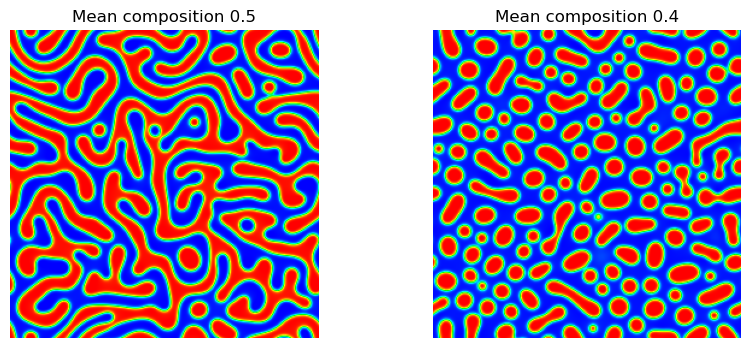

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mean in zip(axes, MEAN_COMPOSITIONS):
    ax.imshow(Image.open(output_folder / f"composition-{mean:.1f}.png"))
    ax.set_title(f"Mean composition {mean}")
    ax.axis("off")
    print(mean, results[f"{mean:.1f}"]["thresholds"]["0.5"])
plt.show()

## Step 11: Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/bicontinuity.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.